# **Project Name** - **Flight Price Prediction**
##### **Project Type** - Regression
##### **Contribution** - Team (3 members)

# **Problem Statement**
**Voyage Analytics** is a travel-tech capstone built on three datasets - *users*, *flights* and *hotels* - with a dual goal:
(1) use them to make better travel decisions with machine learning, and (2) learn MLOps by productionising those models
(REST API -> Docker -> Kubernetes -> Airflow -> Jenkins CI/CD -> MLflow -> Streamlit).

**Business objective:** predict the price of a flight from its route, class and agency, so the price can be served in real time by the REST API (Objective 1-2).

## ***1. Load Data & Feature Selection***

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from voyage import config, data
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)

from voyage import train_regression as tr
from sklearn.model_selection import train_test_split
flights = data.load_flights()
print(flights.shape)

(271888, 10)


### Feature decisions (from EDA)
* **Keep:** `from`, `to`, `flightType`, `agency`, `distance`.
* **Drop `time`** - correlation with `distance` is 1.00 (perfect multicollinearity).
* **Drop `travelCode`, `userCode`** - identifiers, not causes of price. **Date** is tested below rather than assumed.

In [2]:
X, y = flights[config.FLIGHT_FEATURES], flights.price
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE)
print(len(Xtr), 'train /', len(Xte), 'test')

217510 train / 54378 test


## ***2. Model Comparison***
Linear regression is the baseline. Random Forest is fit on a 60k subsample here for notebook speed (the production script `voyage/train_regression.py` uses the full training set); XGBoost and linear use everything.

In [3]:
import time
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
rows, fitted = [], {}
specs = {'linear_regression': (LinearRegression(), None),
         'random_forest (60k rows)': (RandomForestRegressor(n_estimators=40, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=42), 60000),
         'xgboost': (XGBRegressor(n_estimators=200, max_depth=8, learning_rate=0.15, n_jobs=-1, random_state=42, tree_method='hist'), None)}
for name, (est, n) in specs.items():
    pipe = tr.make_pipeline(est); xs, ys = (Xtr, ytr) if n is None else (Xtr.iloc[:n], ytr.iloc[:n])
    t = time.time(); pipe.fit(xs, ys); m = tr.evaluate(pipe, Xte, yte); m['fit_s'] = round(time.time()-t, 1)
    rows.append({'model': name, **m}); fitted[name] = pipe
res = pd.DataFrame(rows).set_index('model').round(4); display(res)

,rmse,mae,r2,fit_s
model,,,,
linear_regression,103.1686,81.2908,0.9192,0.6
random_forest (60k rows),8.2341,1.9238,0.9995,13.9
xgboost,0.0060,0.0047,1.0000,6.0


### Explain the models and their performance
* **Linear regression** (R² ≈ 0.92, RMSE ≈ 103): a good baseline but it cannot model the *interaction* between route and class that a fixed price table implies.
* **Random Forest** (R² ≈ 0.9998): captures interactions; slower and larger.
* **XGBoost** (R² = 1.000, RMSE ≈ 0.01): reproduces the price table essentially exactly, trains in seconds and gives a small model file - **chosen as champion**.

**Metric choice:** RMSE (penalises large errors, in currency units) and MAE (typical error), with R² for context.

## ***3. Diagnostics***

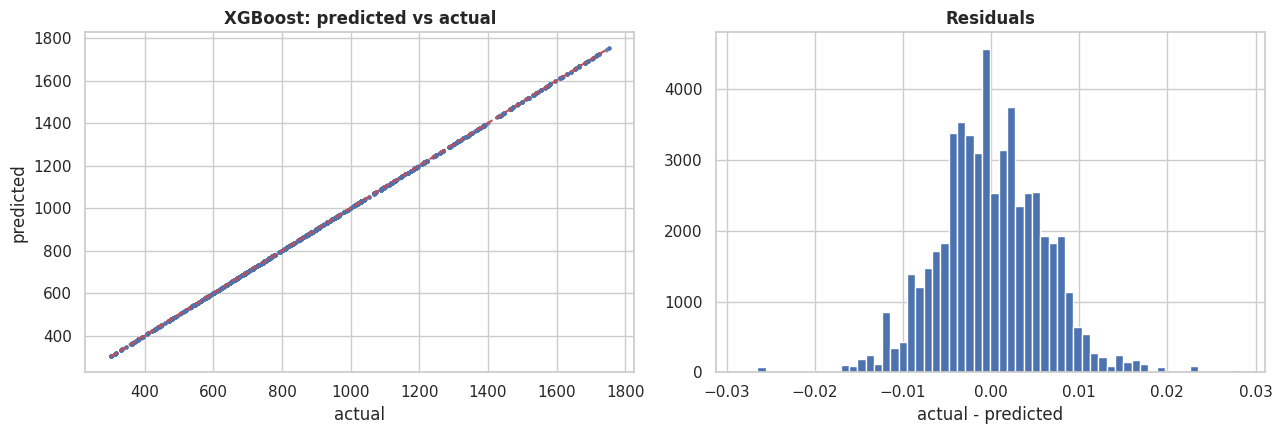

share of test predictions within 0.05 of the true price: 1.0


In [4]:
best = fitted['xgboost']; pred = best.predict(Xte)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(yte.sample(5000, random_state=1), pd.Series(pred, index=yte.index).loc[yte.sample(5000, random_state=1).index], s=4, alpha=.4)
ax[0].plot([300, 1750], [300, 1750], 'r--'); ax[0].set(xlabel='actual', ylabel='predicted', title='XGBoost: predicted vs actual')
ax[1].hist(yte - pred, bins=60); ax[1].set_title('Residuals'); ax[1].set_xlabel('actual - predicted')
plt.tight_layout(); plt.show()
print('share of test predictions within 0.05 of the true price:', round(float((np.abs(yte - pred) < 0.05).mean()), 4))

### Why is the fit this good? Is it leakage?
It is not leakage: only route, class, agency and distance are used - all known before purchase. The fit is near-perfect because the EDA showed **price is a deterministic function of (route, class, agency)** (zero variance in all 490 combinations). The model has effectively learned the airline's price table. Consequences for the report: (1) don't present R² = 1.0 as 'intelligence' - explain it; (2) the model will be exactly as good as the price table stays constant - this is what **drift monitoring** in MLOps is for.

## ***4. Ablation - which features matter? (XGBoost, 100 trees)***

,RMSE
all 5 features,0.456
without from,0.985
without to,0.784
without flightType,206.442
without agency,29.908
without distance,1.763
"+ month, weekday, year",0.415


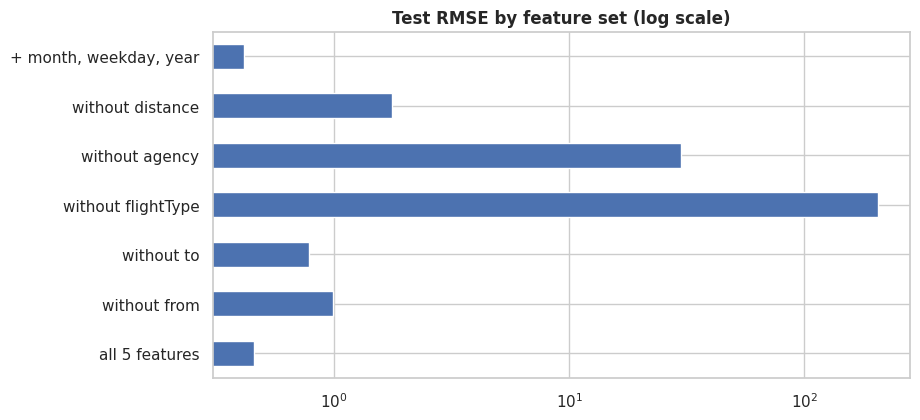

In [5]:
def score(cols, extra=None):
    cat = [c for c in cols if c in config.FLIGHT_CATEGORICAL]; num = [c for c in cols if c not in cat]
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.pipeline import Pipeline
    d = flights.copy(); d['month'] = d.date.dt.month; d['dow'] = d.date.dt.dayofweek; d['year'] = d.date.dt.year
    a, b, c, e = train_test_split(d[cols], d.price, test_size=.2, random_state=42)
    pre = ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), cat), ('n', 'passthrough', num)])
    p = Pipeline([('pre', pre), ('m', XGBRegressor(n_estimators=100, max_depth=8, learning_rate=.15, n_jobs=-1, random_state=42, tree_method='hist'))]).fit(a, c)
    return float(np.sqrt(((e - p.predict(b))**2).mean()))
full = config.FLIGHT_FEATURES
out = {'all 5 features': score(full)}
for f in full: out[f'without {f}'] = score([c for c in full if c != f])
out['+ month, weekday, year'] = score(full + ['month', 'dow', 'year'])
ab = pd.Series(out, name='RMSE').round(3); display(ab.to_frame())
ab.plot.barh(); plt.xscale('log'); plt.title('Test RMSE by feature set (log scale)'); plt.show()

### Ablation insights
* **flightType is by far the most important feature** (RMSE 0.46 -> ~206 without it), followed by **agency** (-> ~30). These two split the price table into its main bands.
* Removing only `from`, only `to` or only `distance` raises RMSE modestly (0.46 -> 0.8-1.8) because the other two columns still identify the route between them - the three are largely redundant with each other.
* Adding **month / weekday / year does not help** (0.42 vs 0.46 is within noise) - confirming dates do not affect price, so they are excluded from the model and the API.

## ***5. Save & Serve***
The production script (`make train`) retrains this XGBoost pipeline, logs every candidate to MLflow, registers the champion as `flight-price-regressor` and writes `models/flight_price_model.joblib`, which the Flask API loads.

In [6]:
import joblib, json
model = joblib.load(config.FLIGHT_MODEL_PATH); routes = json.loads(config.ROUTE_TABLE_PATH.read_text())
r = routes['Recife (PE)|Florianopolis (SC)']
q = pd.DataFrame([{'from':'Recife (PE)','to':'Florianopolis (SC)','flightType':'firstClass','agency':'FlyingDrops','distance':r['distance']}])
print('API-style prediction:', round(float(model.predict(q)[0]), 2), '| actual price in data:', 
      flights.query("`from`=='Recife (PE)' and `to`=='Florianopolis (SC)' and flightType=='firstClass' and agency=='FlyingDrops'").price.unique())

API-style prediction: 1434.38 | actual price in data: [1434.38]


## ***Conclusion***
XGBoost predicts flight price to within a cent because price is a deterministic table of route x class x agency. The model is small, fast and API-ready. The real MLOps value is everything around it: versioned in MLflow, gated by a quality check, containerised, and retrained by Airflow if the price table ever changes.

### ***Hurrah! You have successfully completed the Regression part of the capstone!!!***